In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

Задача: Бинарная классификация академических работ на две категории:
- Human-written (написано человеком)
- AI-Assisted (с использованием ИИ)

Это задача классификации, так как предсказываем категорию

In [2]:
# 1. Прочитать данные
df = pd.read_csv('ai_writing_detection_dataset.csv')
print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

Размер датасета: (10200, 20)

Первые 5 строк:


,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
0,16959e76,Lab_Report,Postgraduate,Native,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,Arial,18,0
1,0a304e7f,Research_Paper,Undergraduate,Native,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,Helvetica,15,0
2,6e629f9f,Essay,Undergraduate,Non_Native,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,Arial,17,1
3,16334d32,Essay,Postgraduate,Native,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,Times New Roman,5,0
4,54d8e254,Essay,Undergraduate,Native,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,Helvetica,8,1


In [3]:
# 5. Обработка пропущенных значений
print("\nКоличество пропусков в каждом столбце:")
print(df.isnull().sum())

# Заполняем числовые пропуски
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns 
categorical_features = df.select_dtypes(include=['object']).columns
for col in numeric_features:
    df[col] = df[col].fillna(df[col].median()) # медианой
for col in categorical_features:
    df[col] = df[col].fillna(df[col].mode()[0]) # модой

# Исключаем лишние признаки
df = df.drop('Student_ID', axis=1)


Количество пропусков в каждом столбце:
Student_ID                    0
Submission_Type               0
Academic_Level                0
Primary_Language              0
Word_Count                    0
Average_Sentence_Length       0
Grammar_Errors                0
Vocabulary_Richness           0
Passive_Voice_Ratio           0
Reading_Level                 0
Editing_Time                889
Revision_Count             1513
Typing_Speed               1003
Plagiarism_Score            813
Citation_Count              993
Punctuation_Density           0
Sentence_Complexity           0
Font_Family                   0
Submission_Hour               0
Is_AI_Assisted                0
dtype: int64


In [4]:
# 2. Разбиение на обучающую и тестовую выборки 
X = df.drop('Is_AI_Assisted', axis=1)
y = df['Is_AI_Assisted']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


Основные статистические характеристики:


,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Submission_Hour,Is_AI_Assisted
count,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000
mean,1201.668627,16.941588,7.336275,0.622392,0.204774,11.479884,162.273098,21.907941,152.615259,6.964234,8.986471,0.053961,1.931613,11.577157,0.145490
std,395.173748,4.635600,5.049967,0.098764,0.096819,2.536711,105.593640,8.679014,338.760180,7.403840,8.734327,0.021689,0.575683,6.942053,0.352612
min,300.000000,5.000000,0.000000,0.290000,0.000000,5.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,925.000000,13.620000,5.000000,0.550000,0.140000,9.700000,119.472500,20.000000,36.167500,2.030000,3.000000,0.040000,1.480000,5.000000,0.000000
50%,1196.000000,17.080000,7.000000,0.620000,0.200000,11.580000,167.660000,24.000000,46.500000,4.640000,5.000000,0.050000,1.930000,12.000000,0.000000
75%,1471.000000,20.640000,9.000000,0.700000,0.270000,13.420000,208.855000,27.000000,57.462500,9.190000,16.000000,0.070000,2.360000,18.000000,0.000000
max,2588.000000,33.620000,78.000000,0.900000,0.520000,20.000000,1493.400000,45.000000,1200.000000,72.330000,36.000000,0.130000,4.060000,23.000000,1.000000



Распределение целевого признака (Is_AI_Assisted):
Is_AI_Assisted
0    0.85451
1    0.14549
Name: proportion, dtype: float64


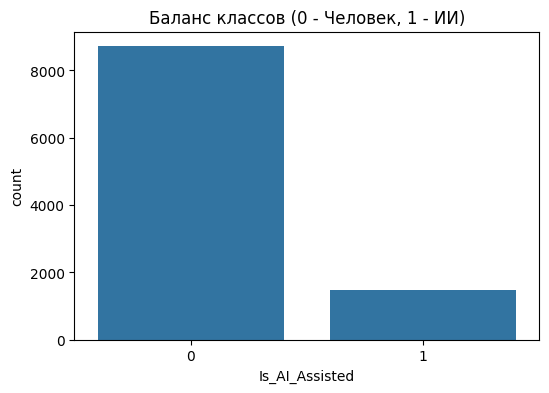

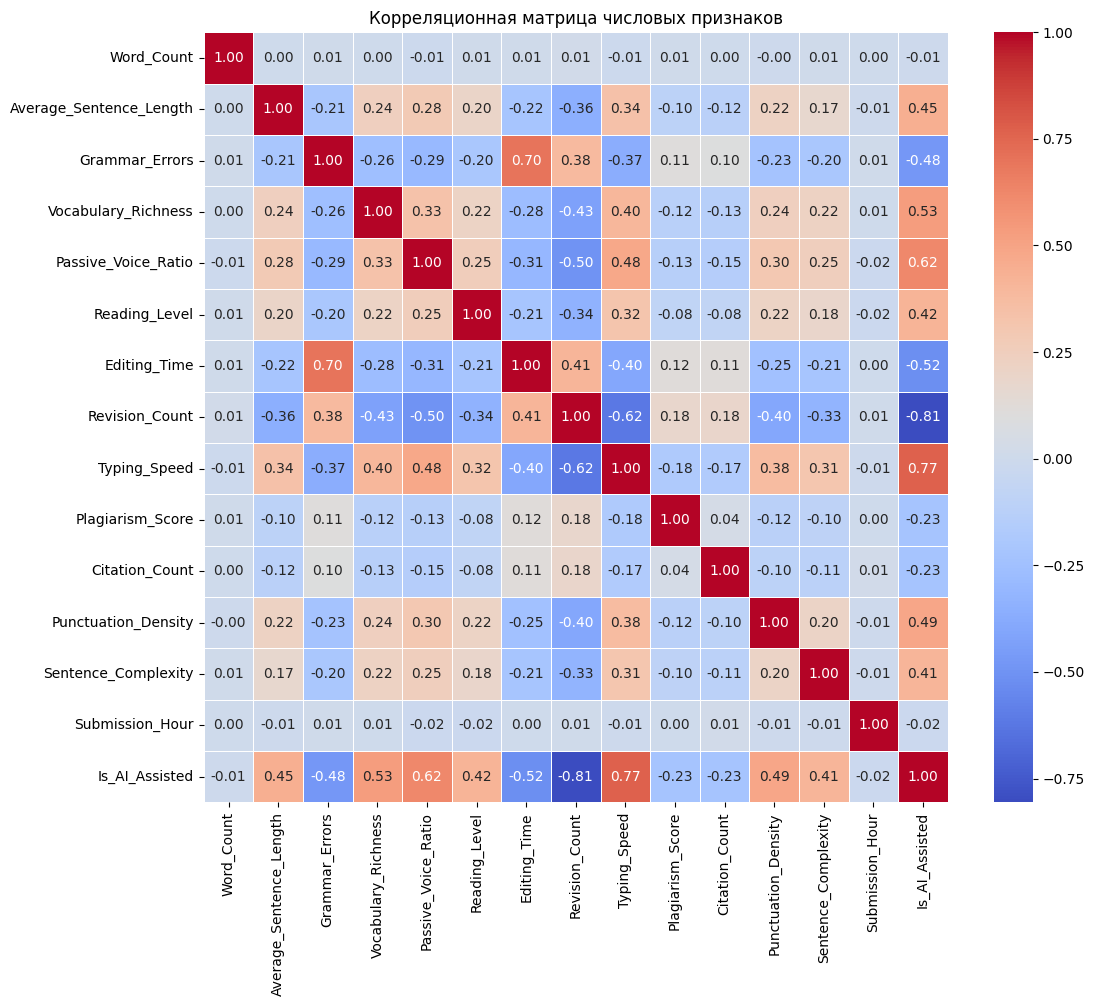

In [5]:
# 3. Визуализация и основные характеристики
print("\nОсновные статистические характеристики:")
display(df.describe())

# баланс классов
print("\nРаспределение целевого признака (Is_AI_Assisted):")
print(df['Is_AI_Assisted'].value_counts(normalize=True))

plt.figure(figsize=(6, 4))
sns.countplot(x='Is_AI_Assisted', data=df)
plt.title('Баланс классов (0 - Человек, 1 - ИИ)')
plt.show()

# корреляция
plt.figure(figsize=(12, 10))
corr = df.select_dtypes(include=['int64', 'float64']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

Наиболее сильную связь с целевой переменной Is_AI_Assisted имеют признаки Revision_Count (отрицательная связь) и Typing_Speed (положительная связь). Это указывает, что скорость набора и отсутствие правок являются главными индикаторами AI-генерации.
При этом крайне малоую связь имеют признаки Word_Count и Submission_Hour, ведь по количеству слов и времени отправки сложно сказать что работа сгенерирована AI.

In [6]:
# 6. Обработка категориальных признаков и 7. Нормализация
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Размерность X_train после предобработки: {X_train_processed.shape}")

Размерность X_train после предобработки: (8160, 27)


8. Запуск классификатора k-ближайших соседей (KNN)

Выбираем именно этот, так как KNN - отличный базовый алгоритм для табличных данных, не делающий строгих предположений о распределении данных

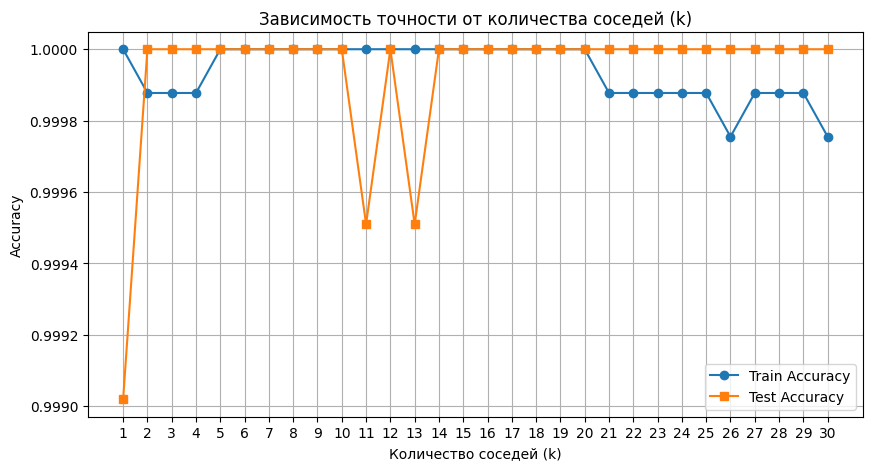


Оптимальное количество соседей k = 2

Матрица рассогласования (Confusion Matrix):


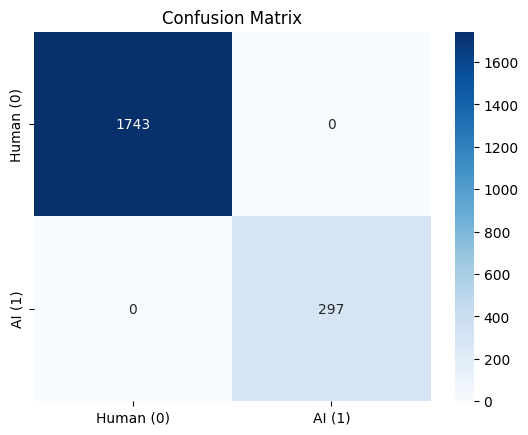


Отчет о классификации (Classification Report):
              precision    recall  f1-score   support

   Human (0)       1.00      1.00      1.00      1743
      AI (1)       1.00      1.00      1.00       297

    accuracy                           1.00      2040
   macro avg       1.00      1.00      1.00      2040
weighted avg       1.00      1.00      1.00      2040



In [7]:
# 9. Подбор оптимального k и вычисление ошибок
k_values = range(1, 31)
train_scores = []
test_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_processed, y_train)
    train_scores.append(accuracy_score(y_train, knn.predict(X_train_processed)))
    test_scores.append(accuracy_score(y_test, knn.predict(X_test_processed)))

plt.figure(figsize=(10, 5))
plt.plot(k_values, train_scores, label='Train Accuracy', marker='o')
plt.plot(k_values, test_scores, label='Test Accuracy', marker='s')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Accuracy')
plt.title('Зависимость точности от количества соседей (k)')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(test_scores)]
print(f"\nОптимальное количество соседей k = {best_k}")

# Обучаем финальную модель
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_processed, y_train)
y_pred = best_knn.predict(X_test_processed)

# Матрица рассогласования и отчет
print("\nМатрица рассогласования (Confusion Matrix):")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Human (0)', 'AI (1)'], yticklabels=['Human (0)', 'AI (1)'])
plt.title('Confusion Matrix')
plt.show()

print("\nОтчет о классификации (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Human (0)', 'AI (1)']))

In [8]:
# 10. Выбираем другой классификатор.
# Случайный лес часто работает лучше на табличных данных и не так чувствителен к масштабу
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_processed, y_train)
y_pred_rf = rf.predict(X_test_processed)

print("\nСравнение моделей:")
print(f"KNN Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nОтчет для Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=['Human (0)', 'AI (1)']))


Сравнение моделей:
KNN Accuracy: 1.0000
Random Forest Accuracy: 1.0000

Отчет для Random Forest:
              precision    recall  f1-score   support

   Human (0)       1.00      1.00      1.00      1743
      AI (1)       1.00      1.00      1.00       297

    accuracy                           1.00      2040
   macro avg       1.00      1.00      1.00      2040
weighted avg       1.00      1.00      1.00      2040



Общие выводы


1. Качество классификации

    Достигнута идеальная точность (100%) на тестовой выборке для обоих алгоритмов (KNN и Random Forest)

    Все метрики (precision, recall, f1-score) равны 1.0 для обоих классов

    Это указывает на то, что признаки в датасете очень хорошо разделяют человеческие и AI-генерированные тексты

2. Наиболее важные признаки
Согласно анализу корреляций, наибольшее влияние на классификацию оказывают:

    Revision_Count (отрицательная корреляция) - AI-тексты имеют меньше правок

    Typing_Speed (положительная корреляция) - AI-тексты создаются быстрее

3. Выбор модели

    KNN с k=2 показал оптимальные результаты

    Random Forest показал аналогичное качество
    Оба алгоритма хорошо справились с задачей, несмотря на дисбаланс классов


4. Характеристики датасета

    10,200 записей с 20 признаками

    Присутствует дисбаланс классов (больше человеческих текстов)
    
    Данные хорошо подготовлены и очищены

5. Практическая значимость
Результаты показывают, что автоматическое обнаружение AI-генерированных академических работ возможно с очень высокой точностью при наличии соответствующих метаданных (скорость набора, количество правок и т.д.).